
# Duka Electronics Board Report — First Half of 2026

## Audience
The Duka Electronics board and CEO. They are non-technical decision-makers who need a concise, phone-readable summary before the board meeting.

## Decision owned by the board
Decide where to focus sales management, marketing attention and commercial investigation during the second half of 2026, based on product, location, channel and monthly revenue evidence.

## Big Idea
**Revenue is concentrated in laptops, Nairobi and online sales, while June revenue is below January. Protect the strongest revenue segments and investigate the decline before committing second-half resources.**

## SCR storyline

- **Situation:** Duka Electronics recorded KES 81.39 million in revenue across 1,000 distinct orders from January through June 2026.
- **Complication:** June revenue was 32.22% lower than January, while laptops, Nairobi and online sales represent substantial portions of total revenue; the dataset alone cannot explain the decline.
- **Resolution:** Review the monthly trend and investigate changes in demand, availability, pricing and conversion, while protecting the leading product, city and channel and testing targeted recovery actions.

## Analytical definitions
- Revenue = quantity × unit_price.
- Distinct order count = the number of unique order IDs.
- Average revenue per order = total order revenue divided by distinct orders.
- Revenue shares are calculated against total revenue for the reporting period.
- The source is `duka_sales.csv`, covering 1 January to 30 June 2026.

## Chart plan
1. Monthly revenue trend — shows the direction of revenue over time.
2. Revenue by product — compares product contribution.
3. Revenue by city — compares geographic contribution.
4. Revenue by channel — shows sales-channel composition.
5. Order revenue distribution — shows variation in order values.

All findings are descriptive. The analysis does not establish causal explanations for changes in revenue.


# Data validation and analysis
The next cell validates the source data, calculates metrics, creates the five report charts and saves the before-and-after images.

In [1]:
from pathlib import Path
import json

import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ============================================================
# DUKA ELECTRONICS: FIRST-HALF 2026 BOARD REPORT
# ============================================================

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_FILE = ROOT / "duka_sales.csv"
REPORT_DIR = ROOT / "reports"
FIGURE_DIR = ROOT / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

REPORT_FILE = REPORT_DIR / "duka_board_report.png"
BEFORE_FILE = FIGURE_DIR / "before.png"
AFTER_FILE = FIGURE_DIR / "after.png"
METRICS_FILE = REPORT_DIR / "board_metrics.json"

HIGHLIGHT = "#E87532"
NEUTRAL = "#C9CED6"
DARK = "#17233B"
MUTED = "#596579"
BACKGROUND = "#FFFFFF"
SOURCE = "Source: duka_sales.csv | Jan-Jun 2026"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": DARK,
    "axes.edgecolor": "#E2E6EC",
    "grid.color": "#E9EDF2",
    "grid.linewidth": 0.7,
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "savefig.facecolor": BACKGROUND,
})


def money(value):
    return f"KES {value:,.0f}"


def add_source(ax):
    ax.text(
        0.0, -0.19, SOURCE,
        transform=ax.transAxes,
        fontsize=7, color=MUTED,
        ha="left", va="top"
    )


def clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)


def label_bars(ax, horizontal=True, money_labels=True):
    if horizontal:
        maximum = max(ax.get_xlim()[1], 1)
        ax.set_xlim(0, maximum * 1.22)
        for patch in ax.patches:
            value = patch.get_width()
            label = money(value) if money_labels else f"{value:,.0f}"
            ax.annotate(
                label,
                (value, patch.get_y() + patch.get_height() / 2),
                xytext=(5, 0), textcoords="offset points",
                va="center", ha="left", fontsize=8,
                color=DARK
            )
    else:
        maximum = max(ax.get_ylim()[1], 1)
        ax.set_ylim(0, maximum * 1.20)
        for patch in ax.patches:
            value = patch.get_height()
            label = money(value) if money_labels else f"{value:,.0f}"
            ax.annotate(
                label,
                (patch.get_x() + patch.get_width() / 2, value),
                xytext=(0, 4), textcoords="offset points",
                va="bottom", ha="center", fontsize=8,
                color=DARK
            )


# ----------------------- Load and validate -------------------

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_FILE}. "
        "Place duka_sales.csv in the project root."
    )

df = pd.read_csv(DATA_FILE)

required = [
    "order_id", "order_date", "branch", "product", "quantity",
    "customer_tier", "channel", "unit_price", "city", "region"
]

missing_columns = [col for col in required if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if df.empty:
    raise ValueError("The dataset contains no records.")

if df[required].isna().any().any():
    raise ValueError("Missing values found. Investigate before reporting.")

if df.duplicated().any():
    raise ValueError("Duplicate rows found. Investigate before reporting.")

df["order_date"] = pd.to_datetime(df["order_date"], errors="raise")
df["quantity"] = pd.to_numeric(df["quantity"], errors="raise")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="raise")

if (df["quantity"] < 0).any() or (df["unit_price"] < 0).any():
    raise ValueError("Negative quantities or prices need investigation.")

df["revenue"] = df["quantity"] * df["unit_price"]
df["month"] = df["order_date"].dt.to_period("M")

if df["order_date"].min() < pd.Timestamp("2026-01-01"):
    raise ValueError("Records before January 2026 found.")

if df["order_date"].max() >= pd.Timestamp("2026-07-01"):
    raise ValueError("Records outside the first half of 2026 found.")

# An order can have multiple rows, so aggregate before counting
orders = (
    df.groupby("order_id", as_index=False)
    .agg(
        order_revenue=("revenue", "sum"),
        order_date=("order_date", "min"),
    )
)

total_revenue = float(df["revenue"].sum())
order_count = int(df["order_id"].nunique())
average_order_revenue = (
    float(orders["order_revenue"].mean()) if order_count else 0.0
)

monthly = df.groupby("month")["revenue"].sum().sort_index()
monthly = monthly.reindex(
    pd.period_range("2026-01", "2026-06", freq="M"),
    fill_value=0
)

jan_revenue = float(monthly.iloc[0])
jun_revenue = float(monthly.iloc[-1])

if jan_revenue:
    change_pct = (jun_revenue - jan_revenue) / jan_revenue * 100
else:
    change_pct = None

if change_pct is None:
    trend_direction = "cannot be calculated because January revenue is zero"
elif change_pct > 0:
    trend_direction = f"increased {change_pct:.1f}% from January to June"
elif change_pct < 0:
    trend_direction = f"declined {abs(change_pct):.1f}% from January to June"
else:
    trend_direction = "was unchanged between January and June"

product_revenue = df.groupby("product")["revenue"].sum().sort_values()
city_revenue = df.groupby("city")["revenue"].sum().sort_values()
channel_revenue = df.groupby("channel")["revenue"].sum().sort_values()

top_product = product_revenue.idxmax()
top_product_revenue = float(product_revenue.max())
top_product_share = top_product_revenue / total_revenue * 100

top_city = city_revenue.idxmax()
top_city_revenue = float(city_revenue.max())
top_city_share = top_city_revenue / total_revenue * 100

top_channel = channel_revenue.idxmax()
top_channel_revenue = float(channel_revenue.max())
top_channel_share = top_channel_revenue / total_revenue * 100

metrics = {
    "period": "2026-01-01 to 2026-06-30",
    "records": int(len(df)),
    "distinct_orders": order_count,
    "total_revenue_kes": round(total_revenue, 2),
    "average_revenue_per_order_kes": round(average_order_revenue, 2),
    "january_revenue_kes": round(jan_revenue, 2),
    "june_revenue_kes": round(jun_revenue, 2),
    "january_to_june_change_pct": (
        round(change_pct, 2) if change_pct is not None else None
    ),
    "top_product": str(top_product),
    "top_product_revenue_kes": round(top_product_revenue, 2),
    "top_product_revenue_share_pct": round(top_product_share, 2),
    "top_city": str(top_city),
    "top_city_revenue_kes": round(top_city_revenue, 2),
    "top_city_revenue_share_pct": round(top_city_share, 2),
    "top_channel": str(top_channel),
    "top_channel_revenue_kes": round(top_channel_revenue, 2),
    "top_channel_revenue_share_pct": round(top_channel_share, 2),
}

METRICS_FILE.write_text(
    json.dumps(metrics, indent=2),
    encoding="utf-8"
)

print("\n========== VALIDATED DATA ==========")
print(f"Rows: {len(df):,}")
print(f"Distinct orders: {order_count:,}")
print(f"Reporting period: {df['order_date'].min().date()} to "
      f"{df['order_date'].max().date()}")
print(f"Total revenue: {money(total_revenue)}")
print(f"Average revenue per order: {money(average_order_revenue)}")
print(f"January-June change: "
      f"{change_pct:.2f}%" if change_pct is not None
      else "January-June change: N/A")
print(f"Top product: {top_product} ({top_product_share:.1f}% of revenue)")
print(f"Top city: {top_city} ({top_city_share:.1f}% of revenue)")
print(f"Top channel: {top_channel} ({top_channel_share:.1f}% of revenue)")


# ------------------ Chart makeover: BEFORE -------------------

fig, ax = plt.subplots(figsize=(9, 5))
before_data = product_revenue.sort_values(ascending=False)

ax.bar(
    before_data.index.astype(str),
    before_data.values,
    color="#4472C4"
)
ax.set_title("Product Revenue")
ax.set_xlabel("Product")
ax.set_ylabel("Revenue")
ax.tick_params(axis="x", rotation=25)
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)
clean_axis(ax)
fig.tight_layout()
fig.savefig(BEFORE_FILE, dpi=180, bbox_inches="tight")
plt.close(fig)


# ------------------- Chart makeover: AFTER ------------------

after_data = product_revenue.sort_values(ascending=True)
top_product_name = after_data.index[-1]

fig, ax = plt.subplots(figsize=(9, 5))
bar_colors = [
    HIGHLIGHT if product == top_product_name else NEUTRAL
    for product in after_data.index
]

ax.barh(after_data.index.astype(str), after_data.values, color=bar_colors)
ax.set_title(
    f"{top_product_name} leads product sales "
    f"with {top_product_share:.1f}% of revenue",
    loc="left", fontsize=13, pad=12
)
ax.set_xlabel("Revenue (KES)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)
clean_axis(ax)
label_bars(ax, horizontal=True, money_labels=True)
add_source(ax)
fig.tight_layout()
fig.savefig(AFTER_FILE, dpi=200, bbox_inches="tight")
plt.close(fig)


# ----------------------- One-page report --------------------

fig = plt.figure(figsize=(16, 11), facecolor=BACKGROUND)
gs = fig.add_gridspec(
    3, 6,
    height_ratios=[0.70, 1.45, 1.45],
    hspace=0.72, wspace=0.75
)

# Executive header
header = fig.add_subplot(gs[0, :])
header.axis("off")
header.text(
    0.0, 0.95,
    "DUKA ELECTRONICS  |  BOARD SALES BRIEF",
    fontsize=10, fontweight="bold", color=HIGHLIGHT,
    transform=header.transAxes, va="top"
)
header.text(
    0.0, 0.57,
    "Protect revenue. Focus the second half.",
    fontsize=24, fontweight="bold", color=DARK,
    transform=header.transAxes, va="top"
)
header.text(
    0.0, 0.15,
    f"JAN-JUN 2026  |  Revenue: {money(total_revenue)}"
    f"  |  Orders: {order_count:,}"
    f"  |  Average per order: {money(average_order_revenue)}",
    fontsize=10, color=MUTED, transform=header.transAxes, va="top"
)

# Chart 1: Monthly trend
ax1 = fig.add_subplot(gs[1, :3])
months_text = [p.strftime("%b") for p in monthly.index]
monthly_values = monthly.values.astype(float)
peak_month = monthly.idxmax().strftime("%B")

ax1.plot(
    months_text, monthly_values,
    color=NEUTRAL, linewidth=2, marker="o",
    markersize=5, markerfacecolor=HIGHLIGHT,
    markeredgecolor=HIGHLIGHT
)
ax1.fill_between(
    range(len(monthly_values)), monthly_values,
    color=HIGHLIGHT, alpha=0.09
)
ax1.set_title(
    f"01 | Revenue {trend_direction}",
    loc="left", fontsize=12, pad=10
)
ax1.set_ylabel("Revenue (KES)")
ax1.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)
ax1.set_xlabel("")
clean_axis(ax1)
add_source(ax1)

# Chart 2: Product comparison
ax2 = fig.add_subplot(gs[1, 3:])
pd_product = product_revenue.sort_values(ascending=True)
product_colors = [
    HIGHLIGHT if p == top_product else NEUTRAL
    for p in pd_product.index
]
ax2.barh(pd_product.index.astype(str), pd_product.values, color=product_colors)
ax2.set_title(
    f"02 | {top_product} is the top product",
    loc="left", fontsize=12, pad=10
)
ax2.set_xlabel("Revenue (KES)")
ax2.set_ylabel("")
ax2.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)
clean_axis(ax2)
label_bars(ax2, horizontal=True, money_labels=True)
add_source(ax2)

# Chart 3: City comparison
ax3 = fig.add_subplot(gs[2, :2])
pd_city = city_revenue.sort_values(ascending=True)
city_colors = [
    HIGHLIGHT if city == top_city else NEUTRAL
    for city in pd_city.index
]
ax3.barh(pd_city.index.astype(str), pd_city.values, color=city_colors)
ax3.set_title(
    f"03 | {top_city} contributes the most",
    loc="left", fontsize=11, pad=9
)
ax3.set_xlabel("Revenue (KES)")
ax3.set_ylabel("")
ax3.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)
clean_axis(ax3)
label_bars(ax3, horizontal=True, money_labels=True)
add_source(ax3)

# Chart 4: Channel composition
ax4 = fig.add_subplot(gs[2, 2:4])
pd_channel = channel_revenue.sort_values(ascending=True)
channel_colors = [
    HIGHLIGHT if channel == top_channel else NEUTRAL
    for channel in pd_channel.index
]
ax4.barh(
    pd_channel.index.astype(str), pd_channel.values,
    color=channel_colors
)
ax4.set_title(
    f"04 | {top_channel} is the leading channel",
    loc="left", fontsize=11, pad=9
)
ax4.set_xlabel("Revenue (KES)")
ax4.set_ylabel("")
ax4.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)
clean_axis(ax4)
label_bars(ax4, horizontal=True, money_labels=True)
add_source(ax4)

# Chart 5: Distribution of order values
ax5 = fig.add_subplot(gs[2, 4:])
ax5.hist(
    orders["order_revenue"],
    bins=12, color=NEUTRAL,
    edgecolor=BACKGROUND, linewidth=1
)
ax5.set_title(
    "05 | Order values vary across customers",
    loc="left", fontsize=11, pad=9
)
ax5.set_xlabel("Revenue per order (KES)")
ax5.set_ylabel("Number of orders")
ax5.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k")
)
clean_axis(ax5)
add_source(ax5)

# Board action footer
fig.text(
    0.055, 0.025,
    "BOARD ACTION  |  Review the monthly trend; protect the strongest product, "
    "city and channel; investigate weaker segments before reallocating budget.",
    fontsize=10, color=DARK, fontweight="bold",
    ha="left", va="bottom"
)
fig.text(
    0.945, 0.025,
    "Internal decision support | Source: duka_sales.csv",
    fontsize=7, color=MUTED, ha="right", va="bottom"
)

fig.savefig(
    REPORT_FILE, dpi=240, bbox_inches="tight",
    facecolor=BACKGROUND
)
plt.close(fig)

print("\n========== OUTPUT FILES ==========")
for path in [REPORT_FILE, BEFORE_FILE, AFTER_FILE, METRICS_FILE]:
    print(f"{'PASS' if path.exists() and path.stat().st_size > 0 else 'FAIL'}"
          f" | {path.relative_to(ROOT)}"
          f" | {path.stat().st_size if path.exists() else 0:,} bytes")

print("\nAnalysis completed.")




========== VALIDATED DATA ==========
Rows: 1,000
Distinct orders: 1,000
Reporting period: 2026-01-01 to 2026-06-30
Total revenue: KES 81,391,500
Average revenue per order: KES 81,392
January-June change: -32.22%
Top product: Laptop (44.4% of revenue)
Top city: Nairobi (30.3% of revenue)
Top channel: Online (55.0% of revenue)



========== OUTPUT FILES ==========
PASS | reports\duka_board_report.png | 432,989 bytes
PASS | figures\before.png | 63,180 bytes
PASS | figures\after.png | 85,421 bytes
PASS | reports\board_metrics.json | 618 bytes

Analysis completed.



# Before-and-after chart makeover

The two images below compare the original product revenue chart with the redesigned version.

## Design changes and reasons

1. **Descending vertical bars to sorted horizontal bars:** horizontal bars make product names easier to read on a phone.
2. **Generic title to an insight-led title:** the redesigned title names the leading product and its share of revenue.
3. **One colour for every bar to one highlight colour:** the leading product is highlighted in orange; other products use neutral grey.
4. **Implicit values to direct labels:** values are displayed on the bars, reducing the need to estimate from an axis.
5. **Generic axes to labelled units:** revenue is explicitly labelled in Kenyan shillings (KES).
6. **No source note to a source line:** readers can identify the data source and reporting period.
7. **Reduced chart clutter:** unnecessary borders and heavy gridlines are removed.

The makeover changes presentation, not the underlying data. The same product revenue aggregation is used in both versions.


figures/before.png


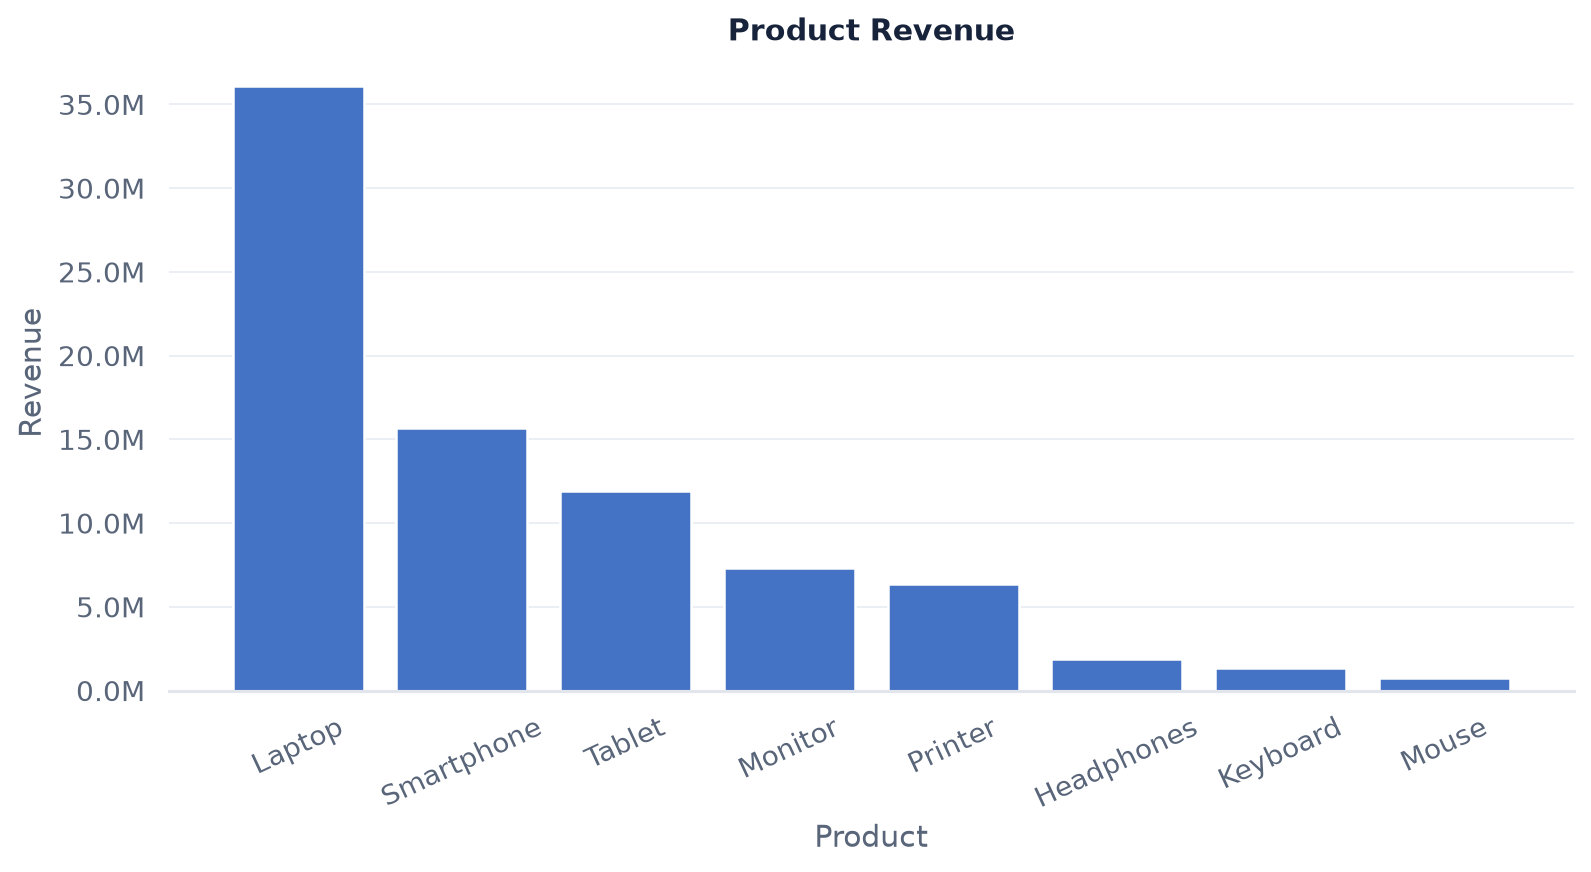

figures/after.png


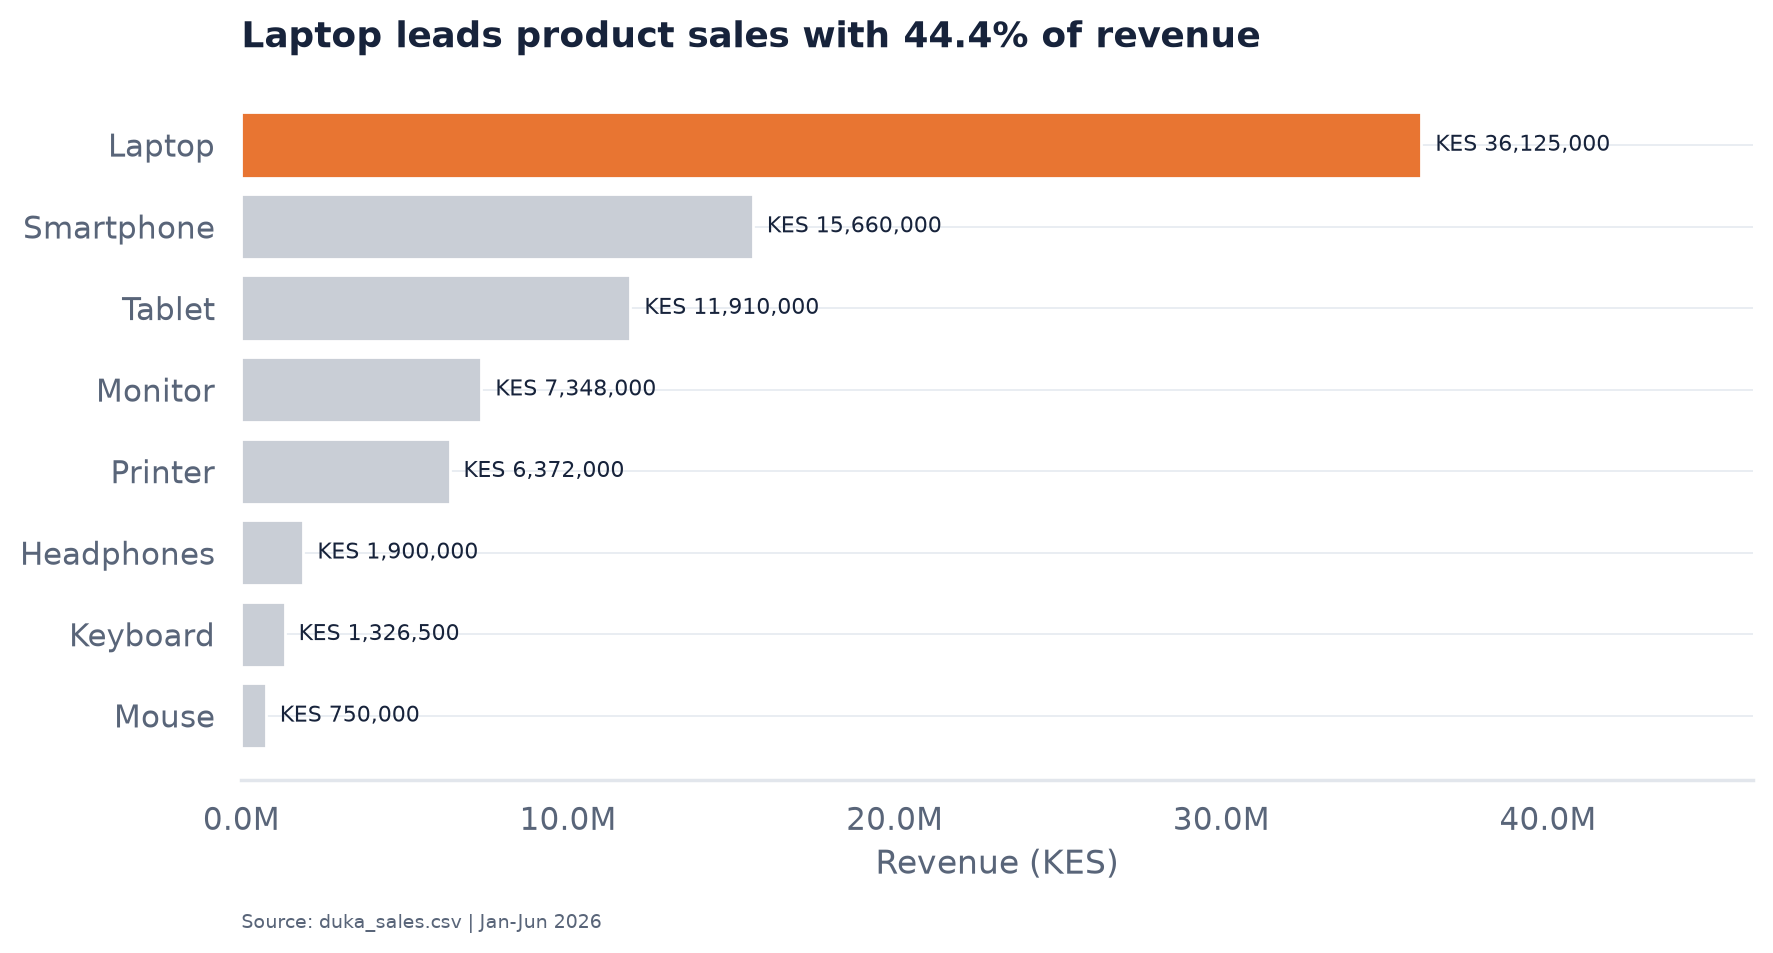

In [2]:
from IPython.display import display, Image
from pathlib import Path

for image_path in [Path('figures/before.png'), Path('figures/after.png')]:
    print(image_path.as_posix())
    display(Image(filename=str(image_path)))

## Board interpretation and limitations

- The January-to-June comparison describes endpoint change; it does not prove that revenue fell continuously in every intervening month.
- Product, city and channel revenue shares identify concentration, not profit or customer acquisition cost.
- The dataset does not provide marketing spend, stock availability, margins, returns or reasons for customer behaviour.
- Before reallocating budgets, investigate monthly performance and validate operational explanations with additional data.
- Use targeted experiments and monitor monthly revenue and order counts in the second half of 2026.